# DISCLAIMER

## The deep learning experiments have been performed on Google Colab to take advantage of the free tier NVIDIA T4 GPU available for efficient deep learning model training. As replicating these experiments on a local environment requires changes to the directory paths found in these notebooks and potentially to the code itself if the user intends to use another GPU/processing unit for these experiments.

# Introduction

The model that I will train on this dataset is the torchgeo's pretrained `resnet-18` encoder model, pretrained on `224x224` `sentinel-2` images having all `13` bands, combined with a regular non-pretrained `UNet` decoder.

Our data has already been converted to patches format and standardized according to the model's requirements. The data is currently in `56x56` resolution patches, therefore an additional x4 upscaling preprocessing step will be applied to batches just before passing them to the model.

# Training stages

The training will be done on the GPU in two stages:

## Stage-1
We will freeze the encoder, and keep the decoder unfrozen. Training will be done with learning rate = 1e-3. This is done to force the model to use previously learned representations and features to make output predictions.

## Stage-2
we will unfreeze both the decoder and encoder and train with a lower learning rate of 1e-4. This will be done to slightly fine-tune the encoder on our specific data involving the segmentation of slums which are quite complex to segment compared to traditional cases of segmenting land, vegetation and water regions. Furthermore, since our data contains three artificially generated zero-bands, we need the encoder to adapt to these changes, and reduce the influence of these bands on predictions.

# Specific details:

### Encoder: Pre-trained Torchgeo Resnet18: SENTINEL2_ALL_MOCO
### Decoder: Non-pretrained UNET
### Hardware: Colab T4 GPU (mixed precision training)
### Data Resolution: 13 bands, 56x56 patches (upscaled to 224x224)
### Train-Val-Test Splits: 3154 : 676 : 676 patches (70% : 15% : 15%)
### Task: Binary classification
### Loss: Jaccard score
### Batch Size: 32
### Learning Rate: Stage-1: 1e-3 | Stage-2: 1e-4

# Install Torchgeo

In [ ]:
!uv pip install torchgeo

Using Python 3.13.15 environment at: /usr
Resolved 98 packages in 844ms
Prepared 15 packages in 483ms
Installed 15 packages in 72ms
 + aenum==3.1.17
 + hydra-core==1.3.7
 + jsonargparse==4.52.0
 + jsonnet==0.22.0
 + kornia==0.8.3
 + kornia-rs==0.2.0
 + lightly==1.5.26
 + lightly-utils==0.0.2
 + lightning==2.6.6
 + lightning-utilities==0.15.3
 + pytorch-lightning==2.6.6
 + segmentation-models-pytorch==0.5.0
 + torchgeo==0.10.1
 + torchmetrics==1.9.0
 + typeshed-client==2.13.0


# Imports

In [ ]:
import numpy as np
import gc

import torch
import torch.nn.functional as F
from torchgeo.models import ResNet18_Weights, resnet18
from torchgeo.trainers import SemanticSegmentationTask
from torch.utils.data import Dataset, DataLoader

import lightning.pytorch as pl
from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
)

import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from pathlib import Path

# Load Google Drive for dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
base_dir = "/content/drive/MyDrive/informal_settlement_segmentation"
data_dir = f"{base_dir}/data/deep_learning"
checkpoints_dir = f"{base_dir}/checkpoints/08"
logs_dir = f"{base_dir}/logs/08"

Mounted at /content/drive


# Setup Pytorch training and validation Datasets and Dataloaders

In [ ]:
class TorchDataset(Dataset):
    def __init__(self, patches): self.patches = patches
    def __len__(self): return len(self.patches)
    def __getitem__(self, idx): return self.patches[idx]

train_dataset = TorchDataset(np.load(data_dir + "/train_patches.npy"))
val_dataset = TorchDataset(np.load(data_dir + "/val_patches.npy"))

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    pin_memory=True,
    num_workers=2,
    persistent_workers=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    pin_memory=True,
    num_workers=2,
    persistent_workers=True,
)

# Load and inspect Torchgeo's resnet18 model pretrained on Sentinel-2 imagery

In [ ]:
weights = ResNet18_Weights.SENTINEL2_ALL_MOCO
print('Weight metadata:')
for key, value in weights.meta.items(): print(f' {key}: {value}')

Weight metadata:
 dataset: SSL4EO-S12
 in_chans: 13
 model: resnet18
 publication: https://arxiv.org/abs/2211.07044
 repo: https://github.com/zhu-xlab/SSL4EO-S12
 ssl_method: moco
 bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8a', 'B9', 'B10', 'B11', 'B12']


# Override segmentation task to add batch upscaling functionality

In [ ]:
class CustomSegmentationTask(SemanticSegmentationTask):
    def on_after_batch_transfer(self, batch, dataloader_idx=0):

        batch = F.interpolate(batch, size=(224, 224), mode="nearest")

        images = batch[:, :-1]
        masks  = batch[:, -1]

        return {"image": images, "mask": masks}

# Stage 1 training

# Prepare and inspect model

In [ ]:
task = CustomSegmentationTask(
    model="unet",
    backbone="resnet18",
    weights=weights,
    in_channels=13,
    task="binary",
    loss="jaccard",
    lr=1e-3,
    freeze_backbone=True,
)

print(task.model)

Downloading: "https://hf.co/torchgeo/resnet18_sentinel2_all_moco/resolve/5b8cddc9a14f3844350b7f40b85bcd32aed75918/resnet18_sentinel2_all_moco-59bfdff9.pth" to /root/.cache/torch/hub/checkpoints/resnet18_sentinel2_all_moco-59bfdff9.pth


100%|██████████| 42.8M/42.8M [00:00<00:00, 47.8MB/s]


Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(13, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, trac

# Check parameter distribution

In [ ]:
encoder_params = sum(p.numel() for p in task.model.encoder.parameters())
decoder_params = sum(p.numel() for p in task.model.decoder.parameters())
head_params = sum(p.numel() for p in task.model.segmentation_head.parameters())

total_params = encoder_params + decoder_params + head_params

print(f"Encoder:     {encoder_params:,}")
print(f"Decoder:     {decoder_params:,}")
print(f"Head:        {head_params:,}")
print(f"Total:       {total_params:,}")

Encoder:     11,207,872
Decoder:     3,151,552
Head:        145
Total:       14,359,569


# Add checkpointing and early stopping functionality

In [ ]:
phase1_best = ModelCheckpoint(
    dirpath=checkpoints_dir,
    filename="best",
    monitor="val_loss",
    mode="min",
    save_top_k=1,
    save_last=True,
)

phase1_periodic = ModelCheckpoint(
    dirpath=checkpoints_dir,
    filename="epoch-{epoch:03d}",
    every_n_epochs=5,
    save_top_k=-1,
)

phase1_early_stop = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=10,
    verbose=True,
)

# Create trainer and logger using Pytorch Lightning

In [ ]:
logger_stage1 = TensorBoardLogger(
    save_dir=logs_dir,
    name="results",
)

trainer_stage1 = pl.Trainer(
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
    max_epochs=100,
    logger=logger_stage1,
    callbacks=[
        phase1_best,
        phase1_periodic,
        phase1_early_stop,
    ],

    log_every_n_steps=1,
)

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
trainer_stage1.fit(
    task,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader,
)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /content/drive/MyDrive/informal_settlement_segmentation/checkpoints exists and is not empty.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ Unet             │ 14.4 M │ train │     0 │
│ 1 │ criterion     │ JaccardLoss      │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ test_metrics  │ MetricCollection │      0 │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 3.2 M                                                                                            
Non-trainable params: 11.2 M                                                                                       
Total params: 14.4 M                                                                                               
Total estimated model params size (MB): 57.438                                                                     
Modules in train mode: 174                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: Metric val_loss improved. New best score: 0.654
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved. New best score: 0.654
INFO: Metric val_loss improved by 0.050 >= min_delta = 0.0. New best score: 0.603
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.050 >= min_delta = 0.0. New best score: 0.603
INFO: Metric val_loss improved by 0.025 >= min_delta = 0.0. New best score: 0.578
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.025 >= min_delta = 0.0. New best score: 0.578
INFO: Metric val_loss improved by 0.013 >= min_delta = 0.0. New best score: 0.565
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.013 >= min_delta = 0.0. New best score: 0.565
INFO: Metric val_loss improved by 0.005 >= min_delta = 0.0. New best score: 0.559
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.005 >= min_delta = 0.0. New best score: 0.559
INFO: Metric val_loss impr

In [ ]:
event_file = next(p for p in Path(logger_stage1.log_dir).glob("events.out.tfevents.*"))

ea = EventAccumulator(str(event_file))
ea.Reload()

for metric in ["train_loss", "val_loss",]:
    events = ea.Scalars(metric)

    print(
        metric,
        "points:", len(events),
        "first step:", events[0].step,
        "last step:", events[-1].step,
    )

train_loss points: 2178 first step: 0 last step: 2177
val_loss points: 22 first step: 98 last step: 2177


In [ ]:
train_losses = [x.value for x in ea.Scalars("train_loss")]
val_losses = [x.value for x in ea.Scalars("val_loss")]

In [ ]:
train_losses_np = np.array(train_losses)

num_epochs = len(val_losses)
steps_per_epoch = len(train_losses_np) // num_epochs

# Reshape: rows = epochs, columns = batches within each epoch
epoch_losses = train_losses_np.reshape(num_epochs, steps_per_epoch)

# Average batch losses within each epoch
train_loss_per_epoch = epoch_losses.mean(axis=1)
train_loss_per_epoch.shape

(22,)

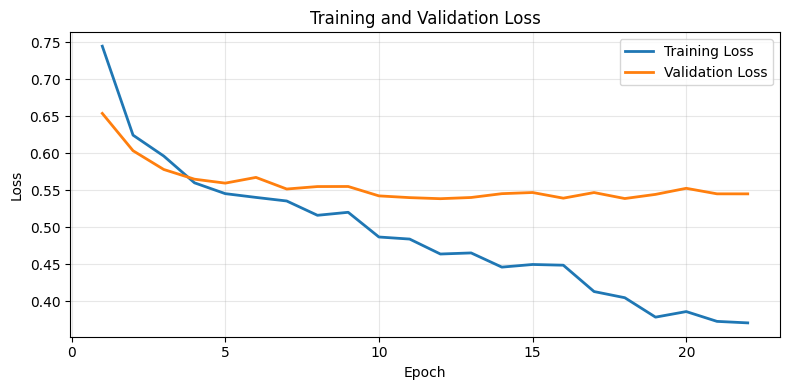

In [ ]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 4))

plt.plot(epochs, train_loss_per_epoch, label="Training Loss", linewidth=2)
plt.plot(epochs, val_losses, label="Validation Loss", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
train_jaccard_scores = [x.value for x in ea.Scalars("train_AverageJaccardIndex")]
val_jaccard_scores = [x.value for x in ea.Scalars("val_AverageJaccardIndex")]

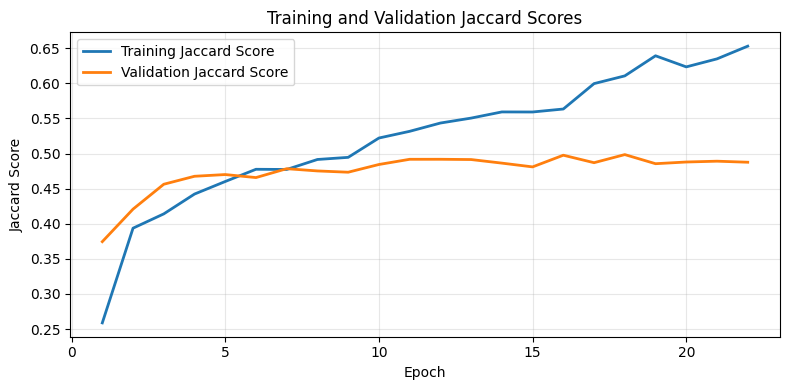

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(epochs, train_jaccard_scores, label="Training Jaccard Score", linewidth=2)
plt.plot(epochs, val_jaccard_scores, label="Validation Jaccard Score", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Jaccard Score")
plt.title("Training and Validation Jaccard Scores")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analysis

The training vs validation loss graphs show that the model started overfitting around epoch 6. Jaccard score graphs further support this theory. Online augmentation will be used in the next experiment to potentially mitigate reduce overfitting and improve generalization.